In [1]:
import pandas as pd

data = pd.read_csv("cleaned_subinstitute_directory_8_27_25.csv")
data.head()

,AffiliationId,SubInstituteId,AffiliationType,InstituteName
0,392282.0,19,institute,ualbany institute for materials
1,392282.0,18,institute,rna institute
2,392282.0,17,institute,ringel institute of gerontology
3,392282.0,16,institute,ordway research institute
4,392282.0,15,institute,nelson a rockefeller institute of government


In [2]:
# find northeastern network science institute

northeastern_institute = data[data['InstituteName'].str.contains('network', case=False)]
northeastern_institute

,AffiliationId,SubInstituteId,AffiliationType,InstituteName
314,1.291213e+07,327,institute,network science institute
536,3.321314e+07,534,institute,institute for networked autonomous systems
1219,7.281631e+07,1196,institute,allegheny health network cancer institute
1267,7.497314e+07,1252,institute,information networking institute
1275,7.497314e+07,1244,institute,allegheny health network research institute
2054,1.110880e+08,2091,institute,network science institute
2582,1.307695e+08,2571,institute,institute for networking and security research
2655,1.353101e+08,2678,institute,intelligent network transportation joint resea...
3327,1.702013e+08,3265,institute,allegheny health network cancer institute
3978,4.210119e+09,3992,institute,network science institute


In [3]:
cleaned_institute = pd.read_csv("cleaned_institute_paa_8_27_25.csv")


In [4]:
network_inst = cleaned_institute[cleaned_institute['AffiliationId'] == 12912129.0]
network_inst

,PublicationId,AuthorId,AffiliationId,SubInstituteId,AuthorSequence,AuthorPosition,IsCorresponding,RawAffiliationString
102745,83986975,5.067483e+09,12912129.0,308,1.0,first,True,"Barnett Institute, Northeastern University, Bo..."
102746,95793680,5.019165e+09,12912129.0,308,1.0,first,False,Departments of Chemistry and Materials Science...
102747,95793680,5.009510e+09,12912129.0,308,2.0,last,False,Departments of Physics and Materials Science D...
102748,2795933649,5.034243e+09,12912129.0,313,1.0,first,False,"Timothy Wang is with the Fenway Institute, Fen..."
102749,2795933649,5.034243e+09,12912129.0,313,1.0,first,False,"Timothy Wang is with the Fenway Institute, Fen..."
...,...,...,...,...,...,...,...,...
108188,2094508150,5.000021e+09,12912129.0,308,2.0,middle,False,Department of Pharmaceutical Sciences in the B...
108189,2094508150,5.043574e+09,12912129.0,308,3.0,last,True,Department of Pharmaceutical Sciences in the B...
108190,4389004552,5.072937e+09,12912129.0,330,1.0,first,True,"360 Huntington Avenue, Department of Health Sc..."
108191,4389004552,5.080904e+09,12912129.0,330,4.0,middle,False,"The Roux Institute, Northeastern University, B..."


In [5]:
network_inst.to_csv("northeastern_network_science_institute.csv", index=False)

Authors: 1,572
Coauthor connections: 4,583
Connected components: 202


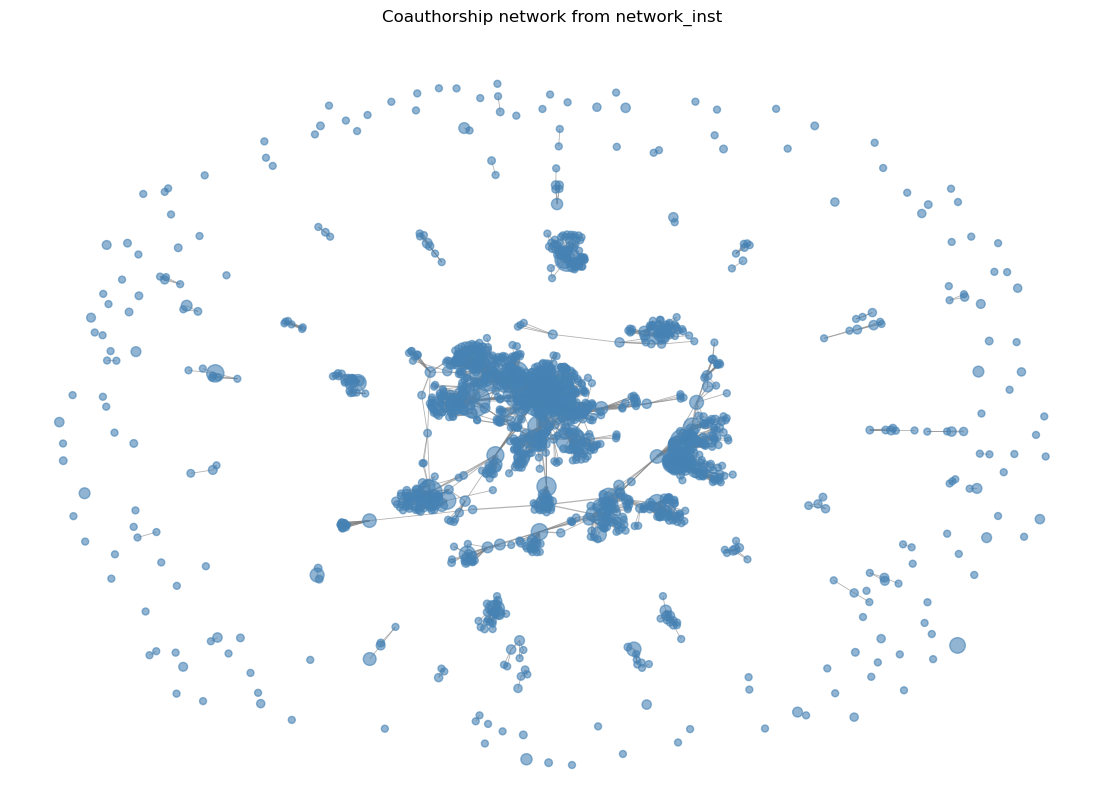

In [6]:
# Coauthorship network: authors are nodes; shared publications create edges.
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations

# An author may appear more than once on a publication in the source data.
author_publications = (
    network_inst[["PublicationId", "AuthorId"]]
    .dropna(subset=["PublicationId", "AuthorId"])
    .drop_duplicates()
)

G = nx.Graph()
# Keep authors with no coauthors as isolated nodes.
for author_id, papers in author_publications.groupby("AuthorId"):
    G.add_node(author_id, publication_count=len(papers))

for publication_id, papers in author_publications.groupby("PublicationId"):
    for author_a, author_b in combinations(papers["AuthorId"], 2):
        if G.has_edge(author_a, author_b):
            G[author_a][author_b]["weight"] += 1
            G[author_a][author_b]["publication_ids"].append(publication_id)
        else:
            G.add_edge(
                author_a, author_b,
                weight=1,
                publication_ids=[publication_id],
            )

print(f"Authors: {G.number_of_nodes():,}")
print(f"Coauthor connections: {G.number_of_edges():,}")
print(f"Connected components: {nx.number_connected_components(G):,}")

# Thicker edges indicate more shared publications; larger nodes have more papers.
fig, ax = plt.subplots(figsize=(14, 10))
pos = nx.spring_layout(G, seed=42, weight="weight", iterations=30)
nx.draw_networkx(
    G, pos=pos, ax=ax,
    with_labels=False,
    node_size=[20 + 5 * G.nodes[node]["publication_count"] for node in G],
    node_color="steelblue",
    width=[0.3 + 0.3 * edge["weight"] for _, _, edge in G.edges(data=True)],
    edge_color="gray",
    alpha=0.6,
)
ax.set_title("Coauthorship network from network_inst")
ax.axis("off")
plt.show()


In [7]:
import pandas as pd
import requests
import time

def fetch_openalex_names(id_list, entity_type, email="zzz2bx@virginia.edu"):
    """
    Fetches display names or titles from OpenAlex for a list of IDs.
    entity_type must be either 'authors' or 'works'.
    """
    # Using an email address puts you in the faster 'Polite Pool'
    headers = {"User-Agent": f"mailto:{email}"}
    results = {}
    
    # OpenAlex permits up to 50 items per filter request
    chunk_size = 50
    for i in range(0, len(id_list), chunk_size):
        chunk = id_list[i:i+chunk_size]
        
        # OpenAlex IDs require an 'A' prefix for authors and 'W' for works
        # This handles raw MAG IDs (numbers) by prepending the correct prefix
        prefix = 'A' if entity_type == 'authors' else 'W'
        formatted_ids = [f"{prefix}{val}" if val.isnumeric() else val for val in chunk]
        
        # Build the batch query URL
        filter_str = "openalex:" + "|".join(formatted_ids)
        url = f"https://api.openalex.org/{entity_type}?filter={filter_str}&per-page={chunk_size}"
        
        try:
            response = requests.get(url, headers=headers)
            response.raise_for_status()
            data = response.json()
            
            for item in data.get('results', []):
                # Isolate the ID from the URL (e.g., 'https://openalex.org/A123' -> 'A123')
                raw_id = item['id'].replace("https://openalex.org/", "")
                
                # Strip the prefix so it maps correctly to numeric MAG IDs in your CSV
                numeric_id = raw_id[1:] if raw_id.startswith(prefix) else raw_id
                
                # Extract the relevant name field
                name = item.get('display_name') if entity_type == 'authors' else item.get('title')
                
                # Store both formats to ensure the mapping works regardless of CSV format
                results[numeric_id] = name
                results[raw_id] = name
                    
        except requests.exceptions.RequestException as e:
            print(f"Error fetching {entity_type} batch {i}: {e}")
            
        # Respect rate limits (Max 10 requests/second for Polite Pool)
        time.sleep(0.1)
        
    return results

# 1. Load the dataset
input_file = "northeastern_network_science_institute.csv"
df = pd.read_csv(input_file)

#remove columns
df = df.drop(columns=['SubInstituteId', 'AuthorSequence', 'AuthorPosition', 'IsCorresponding', 'RawAffiliationString'])  

# Clean IDs (removes potential '.0' if pandas read them as floats)
df['AuthorId'] = df['AuthorId'].astype(str).str.replace(r'\.0$', '', regex=True)
df['PublicationId'] = df['PublicationId'].astype(str).str.replace(r'\.0$', '', regex=True)

# 2. Extract unique IDs to minimize API calls
unique_authors = df['AuthorId'].dropna().unique().tolist()
unique_pubs = df['PublicationId'].dropna().unique().tolist()

print(f"Fetching {len(unique_authors)} unique authors...")
author_mapping = fetch_openalex_names(unique_authors, "authors", email="zzz2bx@virginia.edu")

print(f"Fetching {len(unique_pubs)} unique publications...")
pub_mapping = fetch_openalex_names(unique_pubs, "works", email="zzz2bx@virginia.edu")

# 3. Map the fetched names back to the dataframe as new columns
df['AuthorName'] = df['AuthorId'].map(author_mapping)
df['PublicationName'] = df['PublicationId'].map(pub_mapping)

# 4. Save the enriched dataset
output_file = "enriched_northeastern_network_science_institute.csv"
df.to_csv(output_file, index=False)
print(f"Success! Enriched data saved to {output_file}")

Fetching 1572 unique authors...
Fetching 2332 unique publications...
Success! Enriched data saved to enriched_northeastern_network_science_institute.csv
